# 03 — Outlier và SGD so với nghiệm tối ưu (RQ3, phần SGD của RQ1)

**Câu hỏi:** mô hình huấn luyện bằng SGD kém nghiệm tối ưu (ridge ở λ\*) bao nhiêu, thay đổi thế nào theo dataset và horizon; và khi huấn luyện bằng SGD, DLinear có tốt hơn Linear không? Tương ứng mục 4.1 (đoạn SGD) và 4.3 của báo cáo. Phần outlier của RQ2 nằm ở notebook 02.

**Dữ liệu** (chỉ đọc, xem `results/README.md`):
- B1, B4, C.3 với lr gốc: `results/sgd_b1_b4/summary.json` (JSON từng seed ở `results/sgd_b1_b4/`, `results/sgd_etth2_20seed/`).
- Bản tinh chỉnh lr: `results/nv7/summary.json` (`D_B4`, `D_C3`), `results/sgd_lr/selection.json`.
- Nghiệm dạng đóng: `results/results.csv`.

Quy tắc ba trường hợp: Δ = SGD − dạng đóng, CI 95% của trung bình theo seed trên val và trên test; xem mục 3.8 của báo cáo.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent                     # chạy với thư mục làm việc là notebooks/
sys.path[:0] = [str(ROOT / "scripts" / "report")]
import report_data as D                      # đọc results/ (không ghi gì)
import make_figures as F                     # cùng hàm vẽ với báo cáo LaTeX
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

## B1: SGD (lr gốc) so với số công bố

In [2]:
b1 = pd.DataFrame(D.b1_rows().values()).set_index(["dataset", "H", "model"])
display(b1[["n", "mean", "sd", "min", "max", "pub", "pub_percentile", "pub_inside"]])
print("Số công bố nằm trong [min, max] của các seed:", int(b1.pub_inside.sum()), "/", len(b1))

n    mean      sd     min     max    pub  pub_percentile  pub_inside
dataset H   model                                                                         
ETTh1   96  Linear   20  0.3786  0.0107  0.3715  0.4169  0.375            55.0        True
            DLinear  20  0.3766  0.0057  0.3709  0.3919  0.375            55.0        True
            NLinear  20  0.3779  0.0072  0.3708  0.3963  0.374            25.0        True
        192 Linear   20  0.4250  0.0222  0.4059  0.4774  0.418            55.0        True
            DLinear  20  0.4146  0.0152  0.4054  0.4622  0.405             0.0       False
            NLinear  20  0.4105  0.0106  0.4046  0.4413  0.408            70.0        True
        336 Linear   20  0.4553  0.0189  0.4382  0.5100  0.479            85.0        True
            DLinear  20  0.4573  0.0322  0.4339  0.5400  0.439            45.0        True
            NLinear  20  0.4320  0.0042  0.4283  0.4460  0.429            15.0        True
        720 Linear   20  0.5063  0.0363  0.4727  0.6250  0.624            95.0        True
            DLinear  20  0.5096  0.0396  0.4728  0.5964  0.472             0.0       False
            NLinear  20  0.4363  0.0014  0.4352  0.4411  0.440            95.0        True
ETTh2   96  Linear   20  0.2968  0.0191  0.2792  0.3610  0.288            35.0        True
            DLinear  20  0.2913  0.0060  0.2814  0.3020  0.289            40.0        True
            NLinear  10  0.2770  0.0020  0.2741  0.2806  0.277            60.0        True
        192 Linear   20  0.3961  0.0472  0.3540  0.5227  0.377            45.0        True
            DLinear  20  0.3807  0.0145  0.3621  0.4116  0.383            65.0        True
            NLinear  10  0.3444  0.0041  0.3402  0.3520  0.344            70.0        True
        336 Linear   20  0.4496  0.0241  0.4184  0.5178  0.452            65.0        True
            DLinear  20  0.4529  0.0242  0.4003  0.4862  0.448            40.0        True
            NLinear  10  0.3804  0.0139  0.3666  0.4139  0.357             0.0       False
        720 Linear   20  0.6967  0.0484  0.5962  0.7600  0.698            45.0        True
            DLinear  20  0.6869  0.0592  0.5399  0.7515  0.605            10.0        True
            NLinear  10  0.4058  0.0122  0.3952  0.4340  0.394             0.0       False
ETTm1   96  Linear   20  0.3057  0.0019  0.3043  0.3110  0.308            85.0        True
            DLinear  20  0.3017  0.0018  0.3003  0.3070  0.299             0.0       False
            NLinear  20  0.3091  0.0042  0.3051  0.3186  0.306            35.0        True
        192 Linear   20  0.3401  0.0012  0.3392  0.3432  0.340            70.0        True
            DLinear  20  0.3369  0.0015  0.3351  0.3399  0.335             0.0       False
            NLinear  20  0.3436  0.0028  0.3405  0.3506  0.349            95.0        True
        336 Linear   20  0.3769  0.0025  0.3743  0.3842  0.376            55.0        True
            DLinear  20  0.3731  0.0027  0.3701  0.3783  0.369             0.0       False
            NLinear  20  0.3779  0.0022  0.3757  0.3826  0.375             0.0       False
        720 Linear   20  0.4336  0.0039  0.4289  0.4449  0.440            95.0        True
            DLinear  20  0.4289  0.0028  0.4248  0.4332  0.425             5.0        True
            NLinear  20  0.4346  0.0031  0.4315  0.4406  0.433            45.0        True

Số công bố nằm trong [min, max] của các seed: 28 / 36


## H3: SGD theo seed, nghiệm dạng đóng λ\*, số công bố

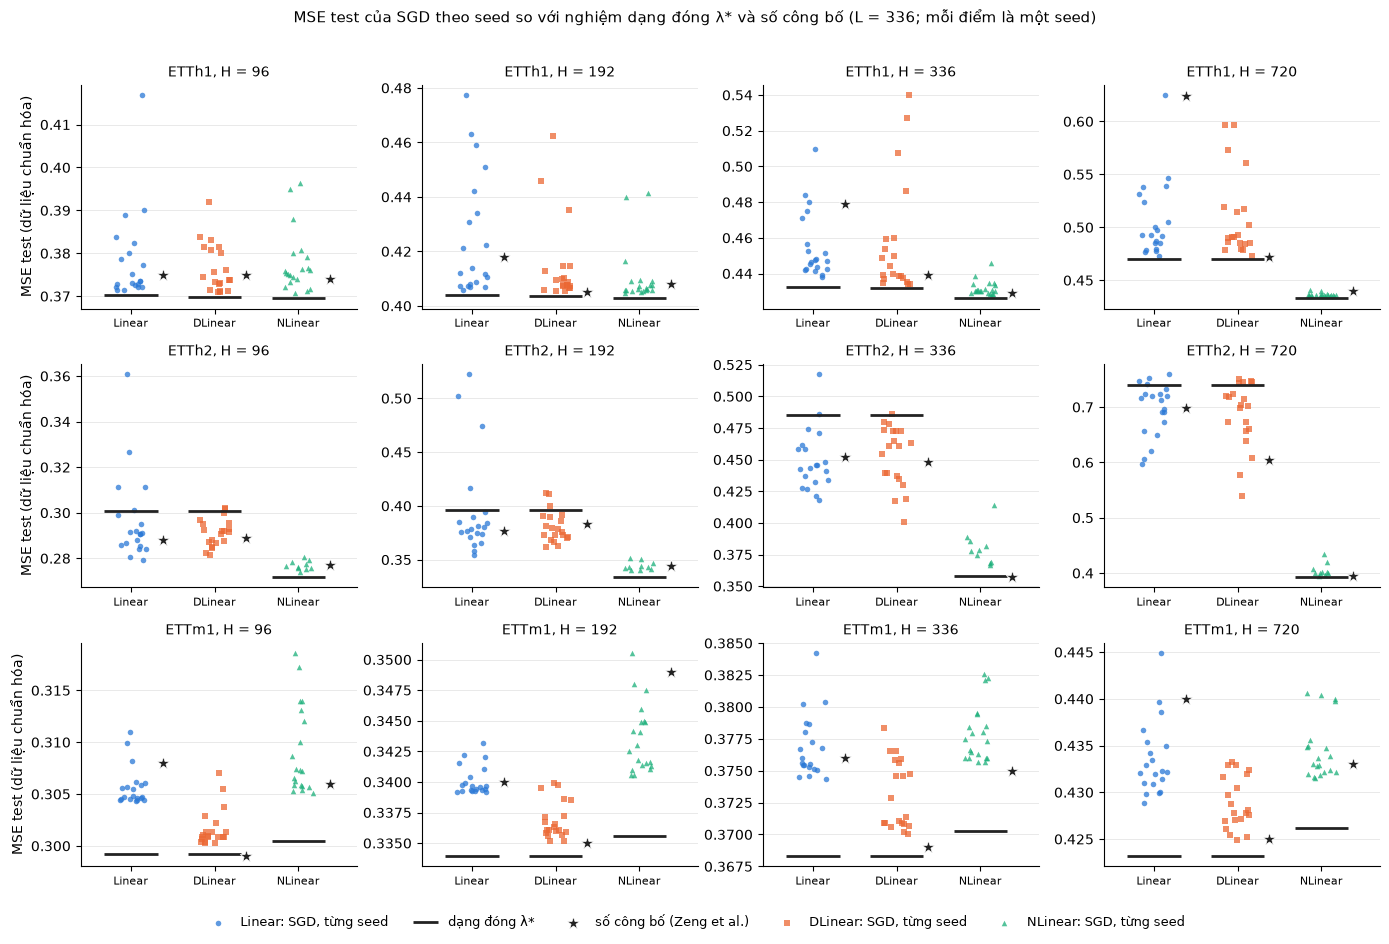

In [3]:
for png in F.capture_png(F.h3):
    display(Image(png))

## B4: SGD − dạng đóng, lr gốc (20 seed) và lr tinh chỉnh (15 seed mới)

In [4]:
old, tuned, lr = D.b4_rows(), D.b4t_rows(), D.lr_cells()
rows = []
for k in old:
    o, t = old[k], tuned[k]
    rows.append({"dataset": k[0], "H": k[1], "model": k[2],
                 "Δ test (lr gốc)": o["d_test"], "CI": o["d_test_ci"], "nhãn (lr gốc)": o["label"],
                 "lr chọn": float(lr[k]["chosen_mult"]),
                 "Δ test (tinh chỉnh)": t["d_test_tuned"], "CI ": t["d_test_ci_tuned"], "nhãn (tinh chỉnh)": t["label_tuned"]})
b4 = pd.DataFrame(rows).set_index(["dataset", "H", "model"])
display(b4)
counts = pd.DataFrame({k: v for k, v in D.nv7()["D_B4"]["counts"].items()},
                      index=["tinh chỉnh, 15 seed", "lr gốc, 15 seed mới", "lr gốc, 20 seed"]).T
display(counts)

Δ test (lr gốc)      CI                     nhãn (lr gốc)  lr chọn  Δ test (tinh chỉnh)     CI                  nhãn (tinh chỉnh)
dataset H   model                                                                                                                                     
ETTh1   96  Linear            0.0083  0.0050  SGD có dấu hiệu khớp val quá mức      4.0               0.0060  0.0031  SGD có dấu hiệu khớp val quá mức
            DLinear           0.0067  0.0027  SGD có dấu hiệu khớp val quá mức      1.0               0.0067  0.0033  SGD có dấu hiệu khớp val quá mức
            NLinear           0.0084  0.0034        khác biệt do val khác test      4.0               0.0067  0.0030  SGD có dấu hiệu khớp val quá mức
        192 Linear            0.0211  0.0104  SGD có dấu hiệu khớp val quá mức      8.0               0.0216  0.0158        khác biệt do val khác test
            DLinear           0.0110  0.0071  SGD có dấu hiệu khớp val quá mức      2.0               0.0075  0.0036        khác biệt do val khác test
            NLinear           0.0078  0.0050        khác biệt do val khác test      4.0               0.0084  0.0088              không phân biệt được
        336 Linear            0.0229  0.0088  SGD có dấu hiệu khớp val quá mức      1.0               0.0259  0.0116  SGD có dấu hiệu khớp val quá mức
            DLinear           0.0256  0.0151  SGD có dấu hiệu khớp val quá mức      0.5               0.0222  0.0149  SGD có dấu hiệu khớp val quá mức
            NLinear           0.0059  0.0020            dạng đóng tốt hơn thật      2.0               0.0039  0.0016        khác biệt do val khác test
        720 Linear            0.0363  0.0170  SGD có dấu hiệu khớp val quá mức      0.5               0.0290  0.0112  SGD có dấu hiệu khớp val quá mức
            DLinear           0.0400  0.0185        khác biệt do val khác test      8.0               0.0198  0.0098        khác biệt do val khác test
            NLinear           0.0034  0.0007            dạng đóng tốt hơn thật      2.0               0.0025  0.0003            dạng đóng tốt hơn thật
ETTh2   96  Linear           -0.0041  0.0089  SGD có dấu hiệu khớp val quá mức      1.0              -0.0020  0.0116              không phân biệt được
            DLinear          -0.0095  0.0028                  SGD tốt hơn thật      1.0              -0.0083  0.0029                  SGD tốt hơn thật
            NLinear           0.0053  0.0014            dạng đóng tốt hơn thật      0.5               0.0052  0.0016            dạng đóng tốt hơn thật
        192 Linear           -0.0005  0.0221              không phân biệt được      4.0              -0.0025  0.0255              không phân biệt được
            DLinear          -0.0159  0.0068                  SGD tốt hơn thật      0.5              -0.0220  0.0082                  SGD tốt hơn thật
            NLinear           0.0108  0.0029        khác biệt do val khác test      0.5               0.0131  0.0042        khác biệt do val khác test
        336 Linear           -0.0357  0.0113                  SGD tốt hơn thật      1.0              -0.0345  0.0131                  SGD tốt hơn thật
            DLinear          -0.0325  0.0113                  SGD tốt hơn thật      1.0              -0.0338  0.0131                  SGD tốt hơn thật
            NLinear           0.0223  0.0099        khác biệt do val khác test      0.5               0.0191  0.0085        khác biệt do val khác test
        720 Linear           -0.0437  0.0226                  SGD tốt hơn thật      0.5              -0.0314  0.0436              không phân biệt được
            DLinear          -0.0534  0.0277                  SGD tốt hơn thật      1.0              -0.0507  0.0298                  SGD tốt hơn thật
            NLinear           0.0134  0.0087        khác biệt do val khác test      0.5               0.0159  0.0073        khác biệt do val khác test
ETTm1   96  Linear            0.0065  0.0009            dạng đóng tốt hơn thật      8.0        

,"tinh chỉnh, 15 seed","lr gốc, 15 seed mới","lr gốc, 20 seed"
SGD tốt hơn thật,5,6,6
dạng đóng tốt hơn thật,2,10,10
khác biệt do val khác test,9,7,7
SGD có dấu hiệu khớp val quá mức,16,11,12
dạng đóng có dấu hiệu khớp val quá mức,0,0,0
không phân biệt được,4,2,1


## DLinear − Linear khi huấn luyện bằng SGD (C.3)

In [5]:
c3, c3t = D.c3_rows(), D.c3t_rows()
c = pd.DataFrame([{"dataset": k[0], "H": k[1],
                   "Δ test lr gốc": c3[k]["d_test"], "CI": c3[k]["d_test_ci"],
                   "DLinear tốt hơn (lr gốc)": c3[k]["dlinear_better_val"] and c3[k]["dlinear_better_test"],
                   "Δ test tinh chỉnh": c3t[k]["d_test"], "CI ": c3t[k]["d_test_ci"],
                   "DLinear tốt hơn (tinh chỉnh)": c3t[k]["dlinear_better_val"] and c3t[k]["dlinear_better_test"],
                   "dạng đóng": c3[k]["cf_d_test"]} for k in c3]).set_index(["dataset", "H"])
display(c)

Δ test lr gốc      CI  DLinear tốt hơn (lr gốc)  Δ test tinh chỉnh     CI   DLinear tốt hơn (tinh chỉnh)   dạng đóng
dataset H                                                                                                                        
ETTh1   96         -0.0020  0.0055                     False             0.0003  0.0043                         False -4.0807e-04
        192        -0.0105  0.0122                     False            -0.0145  0.0161                         False -4.1606e-04
        336         0.0020  0.0170                     False            -0.0043  0.0181                         False -6.4507e-04
        720         0.0033  0.0243                     False            -0.0096  0.0142                         False -4.2022e-04
ETTh2   96         -0.0055  0.0093                     False            -0.0064  0.0118                         False -1.1934e-04
        192        -0.0154  0.0229                     False            -0.0195  0.0264                         False -3.0806e-05
        336         0.0033  0.0154                     False             0.0007  0.0177                         False  2.4304e-06
        720        -0.0098  0.0347                     False            -0.0193  0.0507                         False -2.4174e-05
ETTm1   96         -0.0040  0.0012                      True             0.0002  0.0019                         False -3.4925e-05
        192        -0.0032  0.0009                      True            -0.0010  0.0018                         False -3.7088e-05
        336        -0.0038  0.0017                      True            -0.0020  0.0053                         False -3.8049e-05
        720        -0.0047  0.0022                      True            -0.0020  0.0038                         False -3.7163e-05

## lr đã chọn và độ nhiễu của lựa chọn

In [6]:
sel = pd.DataFrame([{"dataset": k[0], "H": k[1], "model": k[2], "lr gốc": float(v["base_lr"]),
                     **{f"×{m}": float(x) for m, x in v["mean_val_by_mult"].items()},
                     "chọn": float(v["chosen_mult"])} for k, v in D.lr_cells().items()]).set_index(["dataset", "H", "model"])
display(sel)
n, med = D.lr_noisy_count()
print(f"Mức chọn hơn mức thứ hai chưa tới một sai số chuẩn: {n}/36 ô (trung vị khoảng cách/SE = {med:.2f})")

lr gốc    ×0.5      ×1      ×2      ×4  chọn      ×8
dataset H   model                                                        
ETTh2   96  Linear   0.0500  0.2154  0.2151  0.2165  0.2158   1.0     NaN
        192 Linear   0.0500  0.3063  0.3038  0.3095  0.2960   4.0  0.2978
        336 Linear   0.0500  0.4006  0.3946  0.3956  0.3967   1.0     NaN
        720 Linear   0.0500  0.6531  0.6557  0.6549  0.6558   0.5     NaN
        96  DLinear  0.0500  0.2174  0.2156  0.2161  0.2170   1.0     NaN
        192 DLinear  0.0500  0.2958  0.2980  0.3005  0.3017   0.5     NaN
        336 DLinear  0.0500  0.3963  0.3962  0.3985  0.4003   1.0     NaN
        720 DLinear  0.0500  0.6613  0.6612  0.6613  0.6623   1.0     NaN
        96  NLinear  0.0500  0.2055  0.2060  0.2080  0.2147   0.5     NaN
        192 NLinear  0.0500  0.2708  0.2720  0.2772  0.2976   0.5     NaN
        336 NLinear  0.0500  0.3586  0.3606  0.3638  0.3703   0.5     NaN
        720 NLinear  0.0500  0.6037  0.6099  0.6073  0.6150   0.5     NaN
ETTh1   96  Linear   0.0050  0.6503  0.6486  0.6462  0.6448   4.0  0.6597
        192 Linear   0.0050  0.8655  0.8661  0.8645  0.8593   8.0  0.8563
        336 Linear   0.0050  1.0526  1.0415  1.0416  1.0445   1.0     NaN
        720 Linear   0.0050  1.1960  1.2075  1.2131  1.2001   0.5     NaN
        96  DLinear  0.0050  0.6487  0.6480  0.6483  0.6487   1.0     NaN
        192 DLinear  0.0050  0.8728  0.8643  0.8543  0.8565   2.0     NaN
        336 DLinear  0.0050  1.0450  1.0525  1.0493  1.0728   0.5     NaN
        720 DLinear  0.0050  1.2133  1.2223  1.2399  1.2032   8.0  1.2030
        96  NLinear  0.0050  0.6681  0.6771  0.6822  0.6673   4.0  0.6676
        192 NLinear  0.0050  0.9165  0.9210  0.9129  0.9127   4.0  0.9130
        336 NLinear  0.0050  1.1568  1.1543  1.1524  1.1531   2.0     NaN
        720 NLinear  0.0050  1.4308  1.4292  1.4291  1.4292   2.0     NaN
ETTm1   96  Linear   0.0001  0.3922  0.3879  0.3846  0.3820   8.0  0.3815
        192 Linear   0.0001  0.4993  0.4945  0.4914  0.4913   8.0  0.4888
        336 Linear   0.0001  0.6251  0.6198  0.6164  0.6118   8.0  0.6106
        720 Linear   0.0001  0.8762  0.8686  0.8612  0.8617   2.0     NaN
        96  DLinear  0.0001  0.3846  0.3826  0.3813  0.3817   2.0     NaN
        192 DLinear  0.0001  0.4922  0.4892  0.4879  0.4879   2.0     NaN
        336 DLinear  0.0001  0.6173  0.6152  0.6142  0.6135   4.0  0.6177
        720 DLinear  0.0001  0.8681  0.8618  0.8524  0.8563   2.0     NaN
        96  NLinear  0.0001  0.3958  0.3928  0.3903  0.3877   8.0  0.3845
        192 NLinear  0.0001  0.5130  0.5096  0.5060  0.5046   4.0  0.5051
        336 NLinear  0.0001  0.6574  0.6539  0.6519  0.6503   4.0  0.6513
        720 NLinear  0.0001  0.9678  0.9649  0.9625  0.9614   8.0  0.9607

Mức chọn hơn mức thứ hai chưa tới một sai số chuẩn: 26/36 ô (trung vị khoảng cách/SE = 0.56)
